# FEniCSx Practical Exercises · Part II
## Nonlinear PDEs, nonlocal effects and control: Examples 7–11

[Chapter guide](../README.md) · [Setup](../NOTEBOOK_README.md) · [Exercise guide](README.md)

This notebook is self-contained. Select a serial DOLFINx **0.10.x** kernel with
real float64 PETSc and run all cells. Small baseline experiments precede tasks that
require your own parameter sweeps, derivations, and interpretation.

Examples **7, 8, and 10** use actual FEniCSx assembly. Example 10 solves the assembled
FEM matrices with SciPy to make the discrete adjoint visible. Examples **9 and 11**
are explicitly labeled NumPy/SciPy finite-difference models, following the same
implementation distinction as slide scripts 14 and 13. They are not FEniCS solves.
The tasks ask you to formulate and extend these models in FEniCSx.
Suggested duration: three 90-minute sessions.


In [1]:
import platform
import numpy as np
import scipy
from scipy import sparse
from scipy.sparse.linalg import spsolve
from scipy.linalg import eigh
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display
np.set_printoptions(precision=4, suppress=True)
SEED = 7
rng = np.random.default_rng(SEED)
palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449"}
plt.rcParams.update({"figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.labelcolor": palette["ink"], "text.color": palette["ink"],
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 11,
    "axes.titleweight": "bold", "grid.alpha": .35, "lines.linewidth": 2.2,
    "figure.dpi": 100, "legend.frameon": False,
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                      ["teal", "orange", "navy", "pink", "blue"]])})
print(f"Python {platform.python_version()} · NumPy {np.__version__} · SciPy {scipy.__version__}")
print("CPU / float64 / deterministic quadrature / seed", SEED)


Python 3.14.4 · NumPy 2.4.3 · SciPy 1.17.1
CPU / float64 / deterministic quadrature / seed 7


In [2]:
import itertools
from mpi4py import MPI
from petsc4py import PETSc
import dolfinx
from dolfinx import fem, mesh, default_scalar_type
from dolfinx.fem.petsc import LinearProblem, NonlinearProblem, assemble_matrix
import basix.ufl
import ufl
assert MPI.COMM_WORLD.size == 1, "Use a normal serial Jupyter kernel; plotting/CSR conversion here is serial."
assert np.dtype(PETSc.ScalarType) == np.dtype(np.float64), "Select a real-valued float64 PETSc environment."
assert dolfinx.__version__.startswith("0.10."), "These notebooks target DOLFINx 0.10.x; use the documented environment."
print("DOLFINx",dolfinx.__version__,"· PETSc",PETSc.Sys.getVersion())
print("MPI standard",MPI.Get_version(),"·",MPI.Get_library_version().splitlines()[0])
_prefixes=itertools.count()
def prefix(label): return f"notebook_{label}_{next(_prefixes)}_"
def integral(domain, expression):
    form=fem.form(expression*ufl.dx(domain=domain,metadata={"quadrature_degree":8}))
    return float(np.real(domain.comm.allreduce(fem.assemble_scalar(form),op=MPI.SUM)))
def boundary_dofs(V):
    domain=V.mesh; tdim=domain.topology.dim
    domain.topology.create_connectivity(tdim-1,tdim)
    facets=mesh.exterior_facet_indices(domain.topology)
    return fem.locate_dofs_topological(V,tdim-1,facets)
def zero_bc(V): return fem.dirichletbc(default_scalar_type(0.),boundary_dofs(V),V)
def linear_solve(a,L,bcs=(),label="linear"):
    problem=LinearProblem(a,L,bcs=list(bcs),petsc_options_prefix=prefix(label),
          petsc_options={"ksp_type":"preonly","pc_type":"lu","ksp_error_if_not_converged":True})
    solution=problem.solve();solution.x.scatter_forward()
    assert problem.solver.getConvergedReason()>0
    return solution


DOLFINx 0.10.0 · PETSc (3, 25, 0)
MPI standard (5, 0) · MPICH Version:      5.0.0


## 7 · Regularized 3D p-Laplacian — FEniCSx

The baseline solves
$-\nabla\cdot[(\varepsilon^2+|\nabla u|^2)^{(p-2)/2}\nabla u]=f$
on a unit cube with manufactured sine solution and zero Dirichlet data.
This changes the slide example's Neumann/leakage setting to provide an exact error check.

**Task.** Start with $p=2$, then compare $p=2.5,3$ and
$\varepsilon=0.2,0.1,0.05$. Refine the mesh, increase quadrature, and record errors
and Newton iterations. Derive the two contributions to the Jacobian. Finally
restore the slides' homogeneous Neumann condition and positive leakage term,
explaining why that term removes the constant ambiguity.

**Check.** At $p=2$ the mobility is 1 regardless of $\varepsilon$.
A small nonlinear residual does not establish spatial convergence.


In [3]:
def plaplacian_cube(p=2.,epsilon=.1,n=4):
    domain=mesh.create_unit_cube(MPI.COMM_WORLD,n,n,n)
    V=fem.functionspace(domain,("Lagrange",1))
    x=ufl.SpatialCoordinate(domain)
    exact=ufl.sin(np.pi*x[0])*ufl.sin(np.pi*x[1])*ufl.sin(np.pi*x[2])
    mobility_exact=(epsilon**2+ufl.inner(ufl.grad(exact),ufl.grad(exact)))**((p-2)/2)
    source=-ufl.div(mobility_exact*ufl.grad(exact))
    u=fem.Function(V);u.interpolate(lambda x:.8*np.sin(np.pi*x[0])*np.sin(np.pi*x[1])*np.sin(np.pi*x[2]))
    v=ufl.TestFunction(V)
    mobility=(epsilon**2+ufl.inner(ufl.grad(u),ufl.grad(u)))**((p-2)/2)
    dx=ufl.dx(metadata={"quadrature_degree":8})
    F=(mobility*ufl.inner(ufl.grad(u),ufl.grad(v))-source*v)*dx
    problem=NonlinearProblem(F,u,bcs=[zero_bc(V)],petsc_options_prefix=prefix("plaplacian"),
        petsc_options={"snes_type":"newtonls","snes_rtol":1e-9,"snes_atol":1e-10,
                       "snes_max_it":40,"ksp_type":"preonly","pc_type":"lu"})
    problem.solve();u.x.scatter_forward()
    assert problem.solver.getConvergedReason()>0
    return np.sqrt(integral(domain,(u-exact)**2)),problem.solver.getIterationNumber()


In [4]:
# EDIT: create the p/epsilon/mesh study; retain p=2 as a linear reference.
error,iterations=plaplacian_cube(p=2.,epsilon=.1,n=4)
print("p=2 baseline L2 error:",error,"Newton iterations:",iterations)
assert error<.2


p=2 baseline L2 error: 0.08718441572926695 Newton iterations: 1


## 8 · Nonlocal parabolic diffusion — FEniCSx

Here $u_t-\partial_x[a(x)m(t)u_x]=s$, where $m(t)=\int_0^1u(t,x)\,dx$.
The baseline **lags** the mass: use $m^n$ in the diffusion operator for step $n+1$.
This is a semi-implicit scheme, not a fully coupled nonlinear solve.

**Task.** Compare constant and spatially varying $a$, two positive initial profiles,
and two source strengths. Halve the time step and measure differences on a common mesh.
Implement a Picard iteration within each step so the coefficient uses $m^{n+1}$.
Explain what changes if the mass becomes zero or negative.

**Hint.** Assemble the global integral using MPI reduction even though this notebook
runs in serial. Do not substitute an unweighted mean of coefficient values.
**Deliverable.** Mass histories, endpoint checks, and lagged versus iterated results.


In [5]:
def nonlocal_interval(n=40,steps=12,final_time=.06,source_strength=.2):
    domain=mesh.create_unit_interval(MPI.COMM_WORLD,n)
    V=fem.functionspace(domain,("Lagrange",1));x=ufl.SpatialCoordinate(domain)
    old=fem.Function(V);old.interpolate(lambda x:.5*np.sin(np.pi*x[0]))
    old.x.scatter_forward()
    mass=fem.Constant(domain,default_scalar_type(integral(domain,old)))
    u,v=ufl.TrialFunction(V),ufl.TestFunction(V);dt=final_time/steps
    spatial=.2+.1*x[0]
    a=(u*v+dt*mass*spatial*ufl.inner(ufl.grad(u),ufl.grad(v)))*ufl.dx
    L=(old*v+dt*source_strength*v)*ufl.dx
    problem=LinearProblem(a,L,bcs=[zero_bc(V)],petsc_options_prefix=prefix("nonlocal"),
            petsc_options={"ksp_type":"preonly","pc_type":"lu","ksp_error_if_not_converged":True})
    masses=[float(mass.value)]
    for _ in range(steps):
        mass.value=default_scalar_type(integral(domain,old))
        assert float(mass.value)>0, "This lagged model requires positive mass for diffusion."
        new=problem.solve();old.x.array[:]=new.x.array;old.x.scatter_forward()
        masses.append(integral(domain,old))
    coords=V.tabulate_dof_coordinates()[:,0];order=np.argsort(coords)
    return coords[order],old.x.array.real[order],np.linspace(0,final_time,steps+1),np.array(masses)


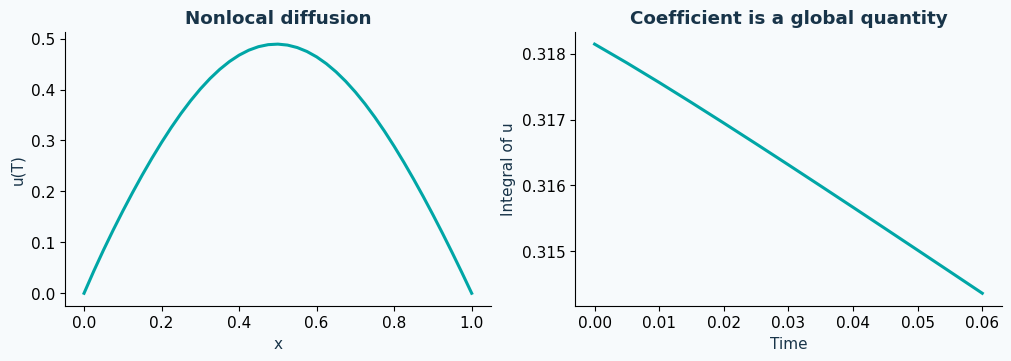

In [6]:
# EDIT: vary source_strength and add the within-step Picard loop.
x,values,t,masses=nonlocal_interval(source_strength=.2)
assert np.max(np.abs(values[[0,-1]]))<1e-12
fig,axs=plt.subplots(1,2,figsize=(10,3.5),layout="constrained")
axs[0].plot(x,values);axs[0].set(xlabel="x",ylabel="u(T)",title="Nonlocal diffusion")
axs[1].plot(t,masses);axs[1].set(xlabel="Time",ylabel="Integral of u",title="Coefficient is a global quantity")
plt.show()


## 9 · Degenerate nonlocal null control — finite-difference starter

This NumPy/SciPy model uses $a(x)=x^\gamma$, $\ell(m)=1+(1+m^2)^{-1}$,
zero reaction, and controls supported in $\omega$. It is a deliberately smaller
variant of [script 14](../experiments/14_degenerate_nonlocal_control.py), whose
reaction is $-20t$. We keep **$0<\gamma<1$** and Dirichlet data at both endpoints.
For $\gamma\ge1$, the appropriate left boundary becomes zero weighted flux;
the supplied routine rejects that regime rather than silently using the wrong condition.

**Task.** First verify uncontrolled decay. Replace a single constant control by
piecewise-constant controls in time and minimize terminal norm plus a control penalty
using `scipy.optimize.minimize`. Compare support intervals and penalties, then restore
the slide reaction term. Report the nonlinear terminal norm after replaying the control;
a frozen linear model's terminal norm is insufficient.

**FEniCS extension.** Write the weighted weak form, derive the nonlocal derivative
$\ell'(m)\int\delta u$, and implement the strong-degeneracy boundary change.
**Check.** This baseline does not compute a null control or demonstrate controllability.


In [7]:
def degenerate_forward(control_amplitude=0.,gamma=.5,n=31,steps=50,final_time=.2,omega=(.3,.7)):
    """Finite differences, c=0, weakly degenerate regime 0<gamma<1, Dirichlet endpoints."""
    assert 0<gamma<1, "For gamma>=1, derive and implement the no-flux left boundary first."
    h=1/(n+1);x=np.arange(1,n+1)*h;dt=final_time/steps
    faces=(np.arange(n+1)+.5)*h
    coeff=faces**gamma
    K=sparse.diags([-coeff[1:-1]/h**2,(coeff[:-1]+coeff[1:])/h**2,-coeff[1:-1]/h**2],[-1,0,1],format="csc")
    mask=((x>omega[0])&(x<omega[1])).astype(float)
    u=2*np.sin(2*np.pi*x);norms=[np.sqrt(h*np.dot(u,u))]
    for _ in range(steps):
        mass=h*u.sum();ell=1+1/(1+mass**2)
        u=spsolve(sparse.eye(n,format="csc")+dt*ell*K,u+dt*control_amplitude*mask)
        norms.append(np.sqrt(h*np.dot(u,u)))
    control_energy=final_time*h*control_amplitude**2*mask.sum()
    return x,u,np.linspace(0,final_time,steps+1),np.array(norms),control_energy


Uncontrolled terminal norm: 0.047623527354729425 control energy: 0.0
Compare against the controlled nonlinear replay, not a frozen prediction.


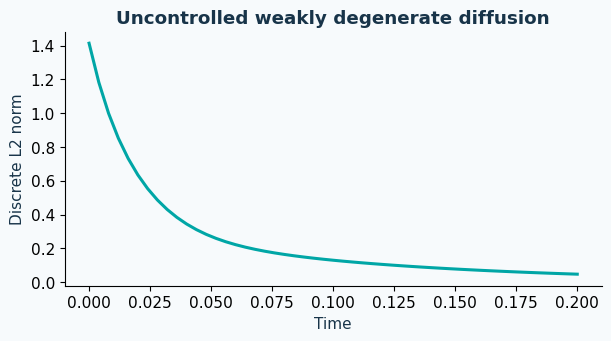

In [8]:
# EDIT: parameterize time-dependent controls and minimize a penalized terminal objective.
x,u,t,norms,control_energy=degenerate_forward(control_amplitude=0.,gamma=.5)
assert norms[-1]<norms[0]
print("Uncontrolled terminal norm:",norms[-1],"control energy:",control_energy)
print("Compare against the controlled nonlinear replay, not a frozen prediction.")
fig,ax=plt.subplots(figsize=(6,3.3),layout="constrained")
ax.plot(t,norms);ax.set(xlabel="Time",ylabel="Discrete L2 norm",title="Uncontrolled weakly degenerate diffusion");plt.show()


## 10 · Heat with drift and an exact discrete adjoint — FEM matrices

FEniCSx assembles $M$, diffusion, and drift for $y_t-\nu y_{xx}+\beta y_x=f$.
Backward Euler gives $Ay^{n+1}=My^n+\Delta tMf^n$.
The cost is $\tfrac12\|y^N-y_T\|_M^2+
\tfrac\alpha2\sum_n\Delta t\|f^n\|_M^2$.
SciPy advances these **FEM matrices** and differentiates the discrete problem using
transposed solves. This is not a finite-difference approximation of the spatial PDE.

**Task.** Derive the backward adjoint recurrence, verify the directional derivative
for several step sizes, then minimize the cost with the supplied gradient. Compare
$\alpha=0.01,0.05,0.2$, reverse the drift, and report the terminal mismatch separately
from control effort. Do not infer successful control from total cost alone.

**Check.** Use the transpose of the discrete operator; changing only the drift sign
without checking mass matrices, time indices, and boundary treatment is not enough.


In [9]:
from scipy.linalg import lu_factor,lu_solve

def drift_control_model(n=24,steps=20,final_time=.2,nu=.03,beta=.5,alpha=.05):
    domain=mesh.create_unit_interval(MPI.COMM_WORLD,n)
    V=fem.functionspace(domain,("Lagrange",1))
    u,v=ufl.TrialFunction(V),ufl.TestFunction(V)
    free=np.setdiff1d(np.arange(V.dofmap.index_map.size_local),boundary_dofs(V))
    def dense(expression):
        A=assemble_matrix(fem.form(expression));A.assemble()
        indptr,indices,data=A.getValuesCSR()
        result=sparse.csr_matrix((data.copy(),indices.copy(),indptr.copy()),shape=A.getSize())
        A.destroy()
        return result[free,:][:,free].toarray()
    M=dense(u*v*ufl.dx)
    operator=dense((nu*ufl.inner(ufl.grad(u),ufl.grad(v))+beta*ufl.grad(u)[0]*v)*ufl.dx)
    coords=V.tabulate_dof_coordinates()[free,0]
    initial=np.exp(-120*(coords-.25)**2);target=np.exp(-120*(coords-.7)**2)
    dt=final_time/steps;A=M+dt*operator;factor=lu_factor(A)
    def objective(controls):
        controls=np.asarray(controls).reshape(steps,len(free))
        states=[initial.copy()]
        for control in controls: states.append(lu_solve(factor,M @ states[-1]+dt*M @ control))
        error=states[-1]-target
        value=.5*error @ M @ error + .5*alpha*dt*np.einsum("ti,ij,tj->",controls,M,controls)
        adjoint=M @ error;gradient=np.zeros_like(controls)
        for k in range(steps-1,-1,-1):
            q=lu_solve(factor,adjoint,trans=1)
            gradient[k]=alpha*dt*(M @ controls[k])+dt*(M.T @ q)
            adjoint=M.T @ q
        return value,gradient,np.array(states)
    return objective,coords,initial,target,(steps,len(free))


Baseline cost: 0.07928977933730157 directional derivative relative defect: 3.740815699618616e-08


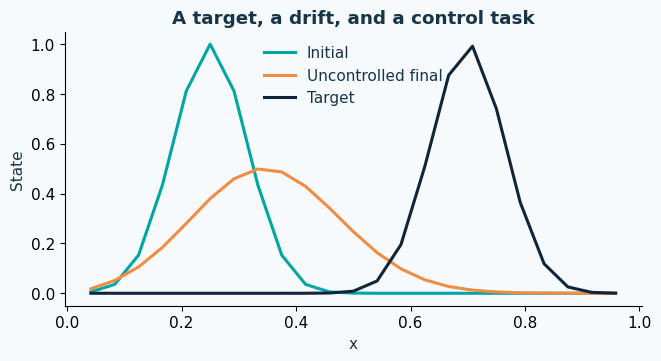

In [10]:
# EDIT: pass objective's value/flattened gradient to scipy.optimize.minimize.
objective,coords,initial,target,shape=drift_control_model()
controls=np.zeros(shape)
value,gradient,states=objective(controls)
direction=rng.normal(size=shape);direction/=np.linalg.norm(direction)
epsilon=1e-5
finite_difference=(objective(controls+epsilon*direction)[0]-objective(controls-epsilon*direction)[0])/(2*epsilon)
adjoint_derivative=np.sum(gradient*direction)
relative_defect=abs(finite_difference-adjoint_derivative)/max(1e-10,abs(finite_difference),abs(adjoint_derivative))
assert relative_defect<1e-5
print("Baseline cost:",value,"directional derivative relative defect:",relative_defect)
order=np.argsort(coords)
fig,ax=plt.subplots(figsize=(6.5,3.5),layout="constrained")
for values,label in [(initial,"Initial"),(states[-1],"Uncontrolled final"),(target,"Target")]:
    ax.plot(coords[order],values[order],label=label)
ax.set(xlabel="x",ylabel="State",title="A target, a drift, and a control task");ax.legend();plt.show()


## 11 · Coupled reaction–diffusion — finite-difference starter

Use the Gray–Scott reactions $R_u=-uv^2+F(1-u)$ and
$R_v=uv^2-(F+k)v$, with zero-flux boundaries. As in
[script 13](../experiments/13_reaction_diffusion_system.py), this starter uses a
cell-centered finite-difference grid with **spacing $h=1$**. Its domain is
$[0,N]^2$, so changing $N$ changes domain size unless $h$ is adjusted as well.

**Task.** Compare two feed/kill pairs, halve $\Delta t$ at fixed final time, and
measure relative field differences. Change $h$ consistently when refining a fixed
domain. Monitor positivity without clipping. Derive the coupled finite element residual
and its four Jacobian blocks, then implement it with a mixed space in FEniCSx.

**Checks.** Diffusion with these no-flux boundaries sums to zero. With $F=k=0$,
the reactions conserve $u+v$; with feed/kill they generally do not.
The explicit diffusion restriction in 2D is $\Delta t\le h^2/(4\max D)$;
reaction dynamics may require a stricter step. A visually plausible pattern is not a convergence test.


In [11]:
def laplacian_neumann(values,h=1.):
    padded=np.pad(values,1,mode="edge")
    return (padded[1:-1,2:]+padded[1:-1,:-2]+padded[2:,1:-1]+padded[:-2,1:-1]-4*values)/h**2

def gray_scott(size=40,steps=300,dt=1.,feed=.06,kill=.062):
    # Cell-centred grid with spacing h=1: domain side length is size, not 1.
    local_rng=np.random.default_rng(SEED)
    u=np.ones((size,size));v=np.zeros_like(u)
    s=slice(size//2-4,size//2+4);u[s,s]=.5;v[s,s]=.25
    v[s,s]+=.01*local_rng.random((8,8))
    for _ in range(steps):
        uvv=u*v*v
        new_u=u+dt*(.16*laplacian_neumann(u)-uvv+feed*(1-u))
        new_v=v+dt*(.08*laplacian_neumann(v)+uvv-(feed+kill)*v)
        u,v=new_u,new_v
    assert np.all(np.isfinite(u)) and np.all(np.isfinite(v))
    return u,v


Ranges: u (np.float64(0.32058431573769397), np.float64(0.9999992449446077)) v (np.float64(1.001665145938764e-12), np.float64(0.4094655251855762))


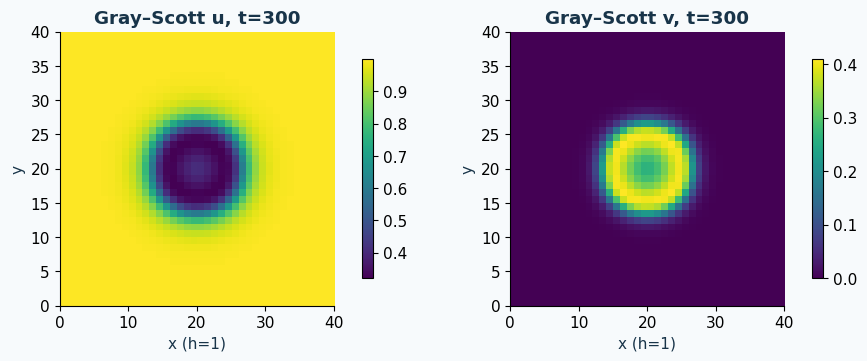

In [12]:
# EDIT: compare parameters and time steps; keep final physical time fixed.
SIZE, STEPS, DT = 40, 300, 1.
u,v=gray_scott(size=SIZE,steps=STEPS,dt=DT)
assert min(u.min(),v.min())>=-1e-12
assert abs(laplacian_neumann(u).sum())<1e-10
reaction_u=-u*v*v;reaction_v=u*v*v
assert np.allclose(reaction_u+reaction_v,0.)
print("Ranges: u",(u.min(),u.max()),"v",(v.min(),v.max()))
fig,axs=plt.subplots(1,2,figsize=(9,3.5),layout="constrained")
for ax,field,name in zip(axs,[u,v],["u","v"]):
    im=ax.imshow(field,origin="lower",cmap="viridis",extent=[0,SIZE,0,SIZE])
    ax.set(xlabel="x (h=1)",ylabel="y",title=f"Gray–Scott {name}, t={STEPS*DT:g}")
    fig.colorbar(im,ax=ax,shrink=.8)
plt.show()


## Submission check

For each example, record the PDE and boundary data, discretization, solver settings,
parameter comparison, numerical verification, and a limitation. Explicitly label
finite-difference results and FEniCSx results. For control tasks, include both the
terminal error and control cost, plus a derivative or nonlinear replay check.

Reference for the solver interface: [DOLFINx 0.10 PETSc API](https://docs.fenicsproject.org/dolfinx/v0.10.0/python/generated/dolfinx.fem.petsc.html).
